In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os
import glob

file_path = '/content/Housing.csv'

if not os.path.exists(file_path):
    csv_files = glob.glob('/content/*.csv')
    if len(csv_files) == 0:
        raise FileNotFoundError("No CSV file found in /content/")
    file_path = csv_files[0]

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("File:", file_path)
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: /content/Housing.csv
Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB
None

Statistical Summary:


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000



Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


In [4]:
print("Missing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nDataset Shape Before Cleaning:", df.shape)

Missing Values:


,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0



Duplicate Records: 0

Dataset Shape Before Cleaning: (545, 13)


In [5]:
features = [
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'parking'
]

target = 'price'

# Select required columns
data = df[features + [target]].copy()

# Convert columns to numeric where possible
for col in features + [target]:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Replace infinite values
data.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove duplicate records
data.drop_duplicates(inplace=True)

# Remove rows containing missing values in selected columns
data.dropna(inplace=True)

print("Data Cleaning Completed!")
print("Shape After Cleaning:", data.shape)

display(data.head())

print("\nMissing Values After Cleaning:")
display(data.isnull().sum())

Data Cleaning Completed!
Shape After Cleaning: (544, 6)


,area,bedrooms,bathrooms,stories,parking,price
0,7420,4,2,3,2,13300000
1,8960,4,4,4,3,12250000
2,9960,3,2,2,2,12250000
3,7500,4,2,2,3,12215000
4,7420,4,1,2,2,11410000



Missing Values After Cleaning:


,0
area,0
bedrooms,0
bathrooms,0
stories,0
parking,0
price,0


In [6]:
X = data[features]
y = data[target]

print("Input Features (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

print("\nNumber of Input Features:", X.shape[1])
print("Number of Records:", X.shape[0])

Input Features (X):


,area,bedrooms,bathrooms,stories,parking
0,7420,4,2,3,2
1,8960,4,4,4,3
2,9960,3,2,2,2
3,7500,4,2,2,3
4,7420,4,1,2,2



Target Variable (y):


,price
0,13300000
1,12250000
2,12250000
3,12215000
4,11410000



Number of Input Features: 5
Number of Records: 544


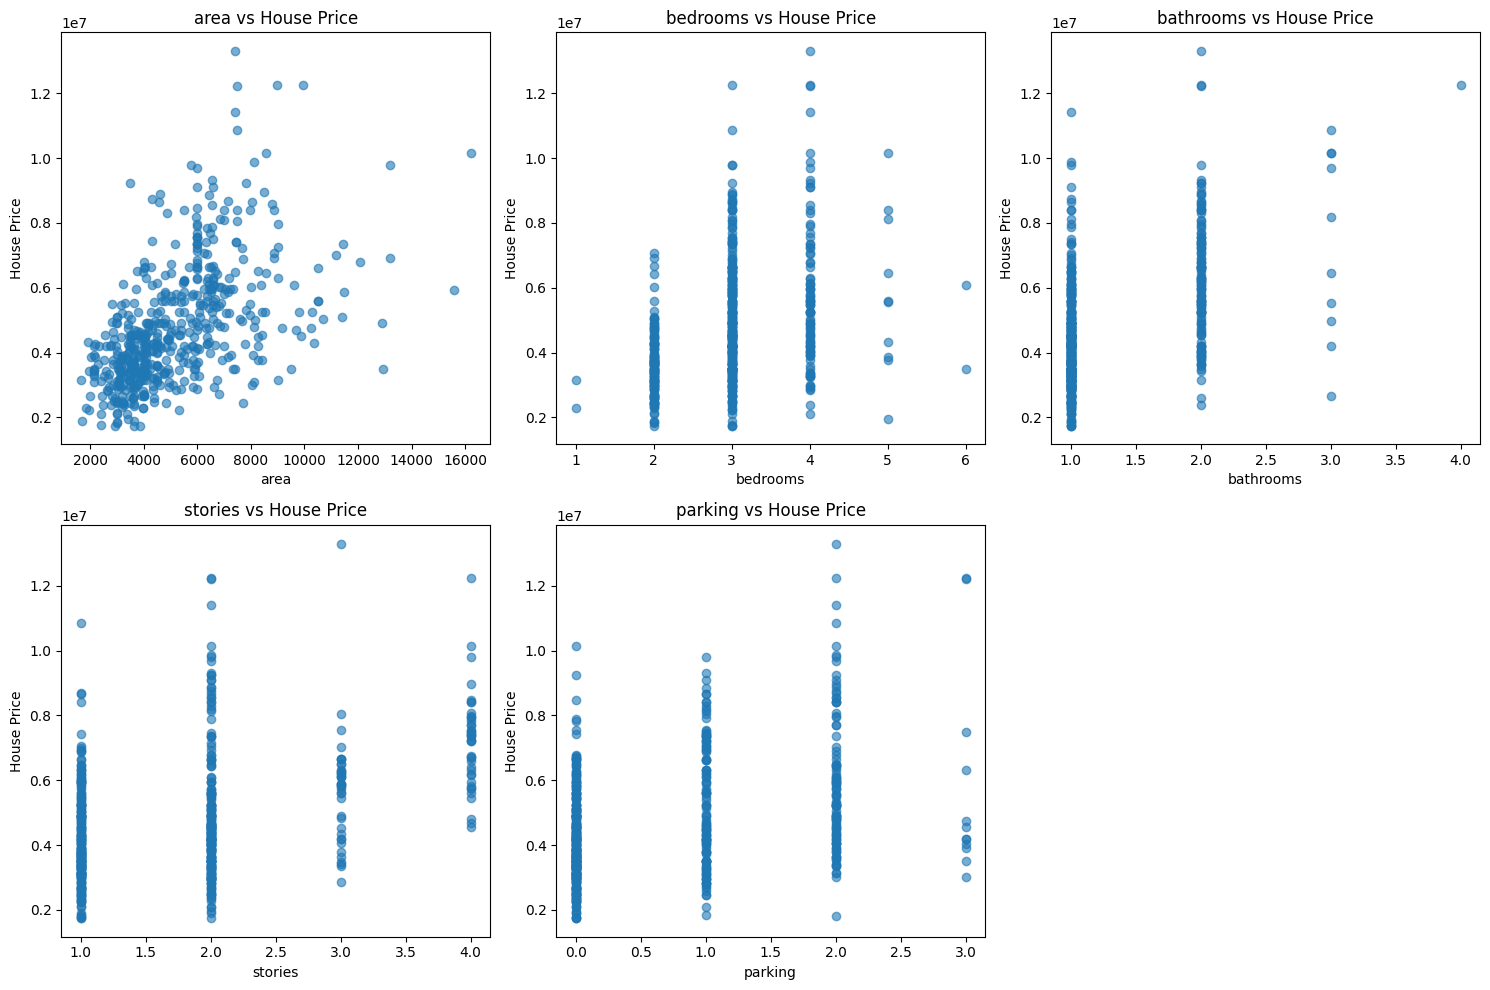

In [7]:
plt.figure(figsize=(15, 10))

for i, feature in enumerate(features):
    plt.subplot(2, 3, i + 1)
    plt.scatter(data[feature], data[target], alpha=0.6)
    plt.xlabel(feature)
    plt.ylabel('House Price')
    plt.title(f'{feature} vs House Price')

plt.tight_layout()
plt.show()

Correlation Matrix:


,area,bedrooms,bathrooms,stories,parking,price
area,1.000000,0.150476,0.193230,0.082901,0.352311,0.535654
bedrooms,0.150476,1.000000,0.373258,0.407293,0.137630,0.365779
bathrooms,0.193230,0.373258,1.000000,0.325546,0.176810,0.517250
stories,0.082901,0.407293,0.325546,1.000000,0.044232,0.420180
parking,0.352311,0.137630,0.176810,0.044232,1.000000,0.383878
price,0.535654,0.365779,0.517250,0.420180,0.383878,1.000000


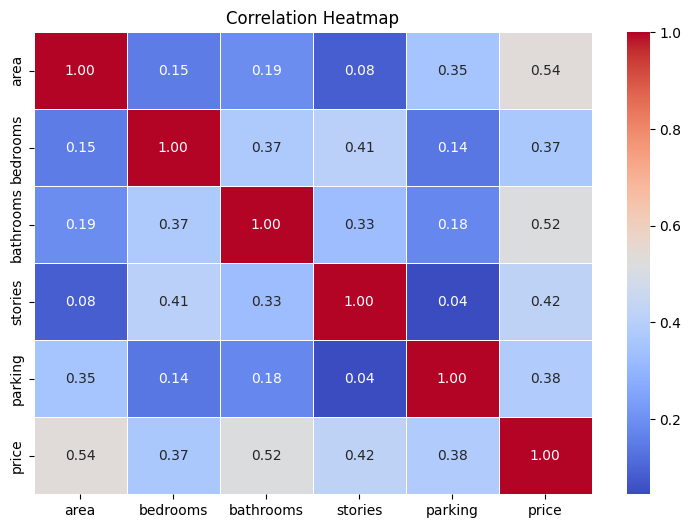

In [8]:
correlation_matrix = data.corr()

print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [9]:
# Select 8 observations for manual calculation
sample = data[['area', 'bedrooms', 'price']].head(8).copy()

X1 = sample['area'].values
X2 = sample['bedrooms'].values
Y = sample['price'].values

# Create design matrix with intercept column
X_manual = np.column_stack([
    np.ones(len(sample)),
    X1,
    X2
])

Y_manual = Y.reshape(-1, 1)

print("Selected 8 Observations:")
display(sample)

print("\nDesign Matrix X:")
print(X_manual)

print("\nTarget Vector Y:")
print(Y_manual)

Selected 8 Observations:


,area,bedrooms,price
0,7420,4,13300000
1,8960,4,12250000
2,9960,3,12250000
3,7500,4,12215000
4,7420,4,11410000
5,7500,3,10850000
6,8580,4,10150000
7,16200,5,10150000



Design Matrix X:
[[1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 8.96e+03 4.00e+00]
 [1.00e+00 9.96e+03 3.00e+00]
 [1.00e+00 7.50e+03 4.00e+00]
 [1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 7.50e+03 3.00e+00]
 [1.00e+00 8.58e+03 4.00e+00]
 [1.00e+00 1.62e+04 5.00e+00]]

Target Vector Y:
[[13300000]
 [12250000]
 [12250000]
 [12215000]
 [11410000]
 [10850000]
 [10150000]
 [10150000]]


In [10]:
X_transpose = X_manual.T

XTX = X_transpose @ X_manual
XTY = X_transpose @ Y_manual

print("X Transpose X:")
print(XTX)

print("\nX Transpose Y:")
print(XTY)

X Transpose X:
[[8.000000e+00 7.354000e+04 3.100000e+01]
 [7.354000e+04 7.381524e+08 2.929000e+05]
 [3.100000e+01 2.929000e+05 1.230000e+02]]

X Transpose Y:
[[9.257500e+07]
 [8.396227e+11]
 [3.573500e+08]]


In [11]:
# Solve the normal equations
beta = np.linalg.pinv(XTX) @ XTY

b0 = beta[0, 0]
b1 = beta[1, 0]
b2 = beta[2, 0]

print("Regression Coefficients:")

print("Intercept (b0):", b0)
print("Area Coefficient (b1):", b1)
print("Bedrooms Coefficient (b2):", b2)

print("\nMultiple Linear Regression Equation:")
print(f"Price = {b0:.2f} + ({b1:.2f} * Area) + ({b2:.2f} * Bedrooms)")

Regression Coefficients:
Intercept (b0): 13147372.710271116
Area Coefficient (b1): -188.09245109369905
Bedrooms Coefficient (b2): 39623.77973152778

Multiple Linear Regression Equation:
Price = 13147372.71 + (-188.09 * Area) + (39623.78 * Bedrooms)


In [12]:
actual_value = Y[0]

predicted_value = b0 + b1 * X1[0] + b2 * X2[0]

residual = actual_value - predicted_value

print("Actual Price:", actual_value)
print("Predicted Price:", predicted_value)
print("Residual:", residual)

Actual Price: 13300000
Predicted Price: 11910221.84208198
Residual: 1389778.1579180192


In [13]:
manual_model = LinearRegression()

manual_model.fit(sample[['area', 'bedrooms']], sample['price'])

print("Library Model Coefficients:")
print("Intercept:", manual_model.intercept_)
print("Area Coefficient:", manual_model.coef_[0])
print("Bedrooms Coefficient:", manual_model.coef_[1])

print("\nManual Calculation Coefficients:")
print("Intercept:", b0)
print("Area Coefficient:", b1)
print("Bedrooms Coefficient:", b2)

print("\nDifference between manual and library coefficients:")
print(beta.flatten() - np.array([
    manual_model.intercept_,
    manual_model.coef_[0],
    manual_model.coef_[1]
]))

Library Model Coefficients:
Intercept: 13147372.708080022
Area Coefficient: -188.0924511067154
Bedrooms Coefficient: 39623.780314441436

Manual Calculation Coefficients:
Intercept: 13147372.710271116
Area Coefficient: -188.09245109369905
Bedrooms Coefficient: 39623.77973152778

Difference between manual and library coefficients:
[ 2.19109468e-03  1.30163471e-08 -5.82913657e-04]


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Data Shape: (435, 5)
Testing Data Shape: (109, 5)

Training Records: 435
Testing Records: 109


In [15]:
train_corr = X_train.join(y_train).corr()['price'].drop('price')

best_feature = train_corr.abs().idxmax()

print("Correlation with House Price:")
display(train_corr.sort_values(key=abs, ascending=False))

print("\nSelected Single Feature:", best_feature)

single_model = LinearRegression()

single_model.fit(X_train[[best_feature]], y_train)

single_predictions = single_model.predict(X_test[[best_feature]])

print("\nSingle Feature Model:")
print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_[0])
print("Test R2 Score:", r2_score(y_test, single_predictions))

Correlation with House Price:


,price
area,0.539722
bathrooms,0.524734
stories,0.410313
bedrooms,0.385484
parking,0.373521



Selected Single Feature: area

Single Feature Model:
Intercept: 2448562.074010263
Coefficient: 440.1929740733586
Test R2 Score: 0.260450461436576


In [16]:
multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

multiple_predictions = multiple_model.predict(X_test)

print("Multiple Linear Regression Model")
print("\nIntercept:", multiple_model.intercept_)

print("\nFeature Coefficients:")

for feature, coefficient in zip(features, multiple_model.coef_):
    print(f"{feature}: {coefficient:.4f}")

print("\nTest R2 Score:", r2_score(y_test, multiple_predictions))

Multiple Linear Regression Model

Intercept: -88149.1232860703

Feature Coefficients:
area: 311.5773
bedrooms: 207489.7433
bathrooms: 1181551.5518
stories: 474539.9604
parking: 374904.0439

Test R2 Score: 0.5336469797647979


In [17]:
equation = f"Price = {multiple_model.intercept_:.2f}"

for feature, coefficient in zip(features, multiple_model.coef_):
    equation += f" + ({coefficient:.2f} * {feature})"

print("Multiple Linear Regression Equation:")
print(equation)

Multiple Linear Regression Equation:
Price = -88149.12 + (311.58 * area) + (207489.74 * bedrooms) + (1181551.55 * bathrooms) + (474539.96 * stories) + (374904.04 * parking)


Standardised Coefficients:


,Feature,Standardised Coefficient
0,area,674887.551819
1,bedrooms,154050.113259
2,bathrooms,558417.464391
3,stories,408254.792159
4,parking,318860.605384


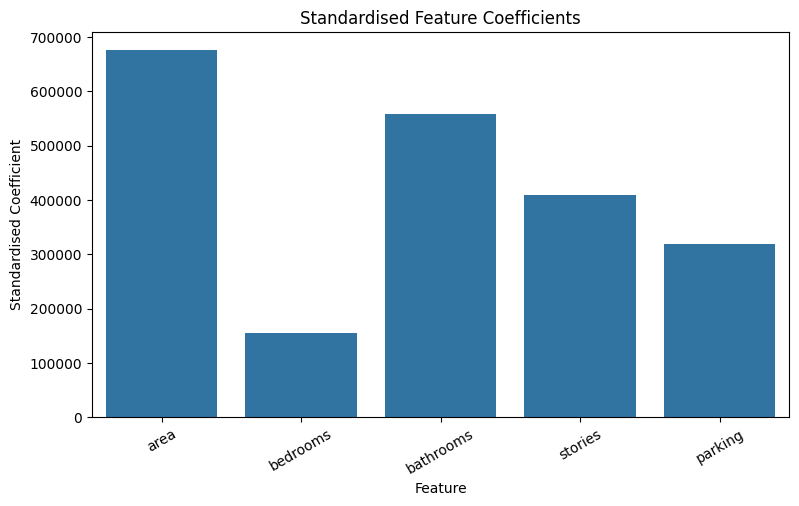

In [18]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

standard_model = LinearRegression()

standard_model.fit(X_train_scaled, y_train)

standardised_coefficients = pd.DataFrame({
    'Feature': features,
    'Standardised Coefficient': standard_model.coef_
})

print("Standardised Coefficients:")
display(standardised_coefficients)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=standardised_coefficients,
    x='Feature',
    y='Standardised Coefficient'
)

plt.title('Standardised Feature Coefficients')
plt.xticks(rotation=30)
plt.show()

In [19]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': multiple_predictions
})

print("Actual vs Predicted House Prices:")
display(comparison.head(10))

Actual vs Predicted House Prices:


,Actual Price,Predicted Price
0,3115000,3.864524e+06
1,4480000,4.760924e+06
2,3773000,5.406576e+06
3,2100000,3.412737e+06
4,1750000,3.097101e+06
5,6650000,6.346295e+06
6,5810000,4.759693e+06
7,6650000,6.321369e+06
8,6510000,4.586290e+06
9,3570000,6.205899e+06


In [20]:
def calculate_metrics(y_actual, y_pred, number_of_features):
    n = len(y_actual)
    r2 = r2_score(y_actual, y_pred)

    adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - number_of_features - 1))

    return {
        'MAE': mean_absolute_error(y_actual, y_pred),
        'MSE': mean_squared_error(y_actual, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_actual, y_pred)),
        'R2 Score': r2,
        'Adjusted R2': adjusted_r2
    }

multiple_metrics = calculate_metrics(
    y_test,
    multiple_predictions,
    X_test.shape[1]
)

single_metrics = calculate_metrics(
    y_test,
    single_predictions,
    1
)

print("Multiple Linear Regression Evaluation:")
for metric, value in multiple_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nSingle Feature Regression Evaluation:")
for metric, value in single_metrics.items():
    print(f"{metric}: {value:.4f}")

Multiple Linear Regression Evaluation:
MAE: 1141982.0301
MSE: 2295578854720.5713
RMSE: 1515116.7792
R2 Score: 0.5336
Adjusted R2: 0.5110

Single Feature Regression Evaluation:
MAE: 1458975.3017
MSE: 3640363006308.6772
RMSE: 1907973.5340
R2 Score: 0.2605
Adjusted R2: 0.2535


In [21]:
model_comparison = pd.DataFrame({
    'Metric': list(single_metrics.keys()),
    'Single Feature Model': list(single_metrics.values()),
    'Multiple Feature Model': list(multiple_metrics.values())
})

print("Model Performance Comparison:")
display(model_comparison)

Model Performance Comparison:


,Metric,Single Feature Model,Multiple Feature Model
0,MAE,1.458975e+06,1.141982e+06
1,MSE,3.640363e+12,2.295579e+12
2,RMSE,1.907974e+06,1.515117e+06
3,R2 Score,2.604505e-01,5.336470e-01
4,Adjusted R2,2.535388e-01,5.110085e-01


Residual Values:


,Predicted Price,Residuals
0,3.864524e+06,-7.495241e+05
1,4.760924e+06,-2.809241e+05
2,5.406576e+06,-1.633576e+06
3,3.412737e+06,-1.312737e+06
4,3.097101e+06,-1.347101e+06
5,6.346295e+06,3.037046e+05
6,4.759693e+06,1.050307e+06
7,6.321369e+06,3.286308e+05
8,4.586290e+06,1.923710e+06
9,6.205899e+06,-2.635899e+06


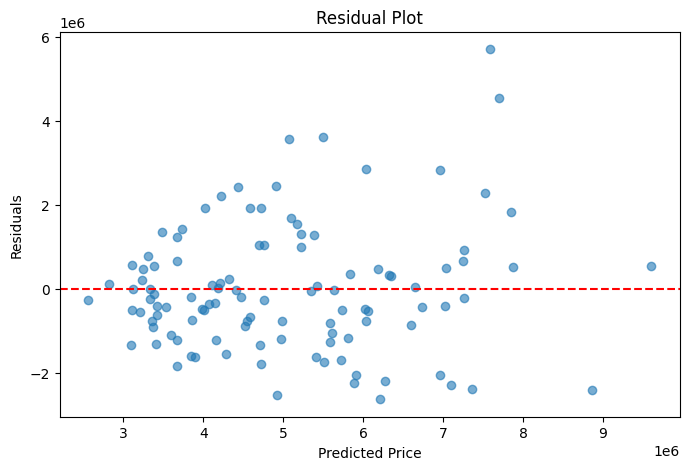

In [22]:
residuals = y_test.values - multiple_predictions

residual_data = pd.DataFrame({
    'Predicted Price': multiple_predictions,
    'Residuals': residuals
})

print("Residual Values:")
display(residual_data.head(10))

plt.figure(figsize=(8, 5))

plt.scatter(
    multiple_predictions,
    residuals,
    alpha=0.6
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.show()

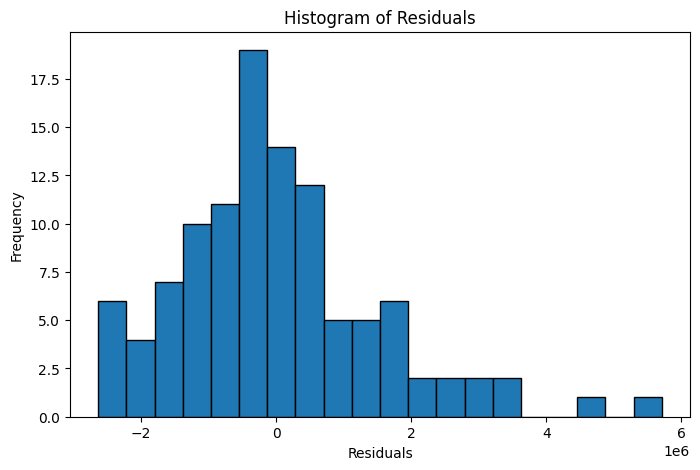

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=20, edgecolor='black')

plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Histogram of Residuals')

plt.show()

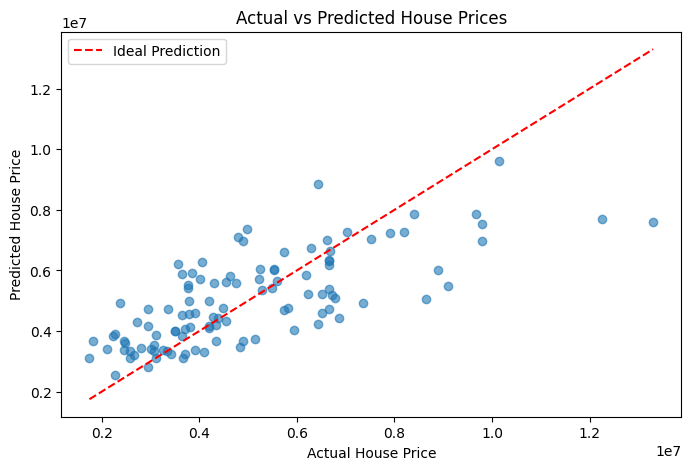

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    multiple_predictions,
    alpha=0.6
)

min_value = min(y_test.min(), multiple_predictions.min())
max_value = max(y_test.max(), multiple_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label='Ideal Prediction'
)

plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Actual vs Predicted House Prices')
plt.legend()

plt.show()

In [25]:
vif_data = pd.DataFrame()

vif_data['Feature'] = X_train.columns

vif_data['VIF'] = [
    variance_inflation_factor(
        X_train.values,
        i
    )
    for i in range(X_train.shape[1])
]

print("Variance Inflation Factor:")
display(vif_data)

Variance Inflation Factor:


,Feature,VIF
0,area,1.166883
1,bedrooms,1.324146
2,bathrooms,1.243145
3,stories,1.259325
4,parking,1.137222


In [26]:
train_predictions = multiple_model.predict(X_train)
test_predictions = multiple_model.predict(X_test)

train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)

print("Training R2 Score:", train_r2)
print("Testing R2 Score:", test_r2)

if train_r2 - test_r2 > 0.15:
    print("\nThe model may be overfitting.")
else:
    print("\nNo large train-test R2 gap detected.")

Training R2 Score: 0.5679087211947405
Testing R2 Score: 0.5336469797647979

No large train-test R2 gap detected.


In [27]:
new_house = pd.DataFrame(
    [X_train.median().values],
    columns=features
)

print("New House Details:")
display(new_house)

new_prediction = multiple_model.predict(new_house)

print("\nPredicted House Price:", new_prediction[0])

New House Details:


,area,bedrooms,bathrooms,stories,parking
0,4500.0,3.0,1.0,2.0,0.0



Predicted House Price: 4067049.317168046


In [28]:
print("=" * 50)
print("MULTIPLE LINEAR REGRESSION - FINAL SUMMARY")
print("=" * 50)

print("\nDataset Records:", len(data))
print("Input Features:", features)
print("Target Variable:", target)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nRegression Equation:")
print(equation)

print("\nModel Evaluation:")
for metric, value in multiple_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nNew House Predicted Price:", new_prediction[0])

print("\nSingle Feature R2:", single_metrics['R2 Score'])
print("Multiple Feature R2:", multiple_metrics['R2 Score'])

print("\nActivity 1 Completed Successfully!")

MULTIPLE LINEAR REGRESSION - FINAL SUMMARY

Dataset Records: 544
Input Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Target Variable: price

Training Records: 435
Testing Records: 109

Regression Equation:
Price = -88149.12 + (311.58 * area) + (207489.74 * bedrooms) + (1181551.55 * bathrooms) + (474539.96 * stories) + (374904.04 * parking)

Model Evaluation:
MAE: 1141982.0301
MSE: 2295578854720.5713
RMSE: 1515116.7792
R2 Score: 0.5336
Adjusted R2: 0.5110

New House Predicted Price: 4067049.317168046

Single Feature R2: 0.260450461436576
Multiple Feature R2: 0.5336469797647979

Activity 1 Completed Successfully!


In [29]:
print("DECISION LOG")
print("-" * 50)

print("1. Dataset: Housing Prices Dataset")
print("2. Target: House Price")
print("3. Selected Features:", features)
print("4. Missing values and duplicates were checked.")
print("5. An 80:20 train-test split was used.")
print("6. Linear Regression was used for prediction.")
print("7. MAE, MSE, RMSE, R2 and Adjusted R2 were calculated.")
print("8. Multicollinearity was checked using VIF.")

print("\nCONCLUSION")
print("-" * 50)

if multiple_metrics['R2 Score'] > single_metrics['R2 Score']:
    print("The multiple-feature model achieved a higher test R2 score.")
else:
    print("The multiple-feature model did not improve the test R2 score.")

print("The model predicts house prices using multiple numerical features.")
print("Residual analysis was performed to examine prediction errors.")
print("VIF was used to identify possible multicollinearity.")
print("The model provides estimates and not guaranteed house prices.")
print("Linear regression may not capture all non-linear relationships.")

DECISION LOG
--------------------------------------------------
1. Dataset: Housing Prices Dataset
2. Target: House Price
3. Selected Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
4. Missing values and duplicates were checked.
5. An 80:20 train-test split was used.
6. Linear Regression was used for prediction.
7. MAE, MSE, RMSE, R2 and Adjusted R2 were calculated.
8. Multicollinearity was checked using VIF.

CONCLUSION
--------------------------------------------------
The multiple-feature model achieved a higher test R2 score.
The model predicts house prices using multiple numerical features.
Residual analysis was performed to examine prediction errors.
VIF was used to identify possible multicollinearity.
The model provides estimates and not guaranteed house prices.
Linear regression may not capture all non-linear relationships.
